📌** Feature Engineering - Introduction**

🔹 What is Feature Engineering?

Feature Engineering is the process of transforming raw data into useful features that help machine learning models perform better.

👉 In simple terms: We convert data into a form that machines can understand easily.



In [ ]:
from google.colab import files

uploaded = files.upload()

Saving BankChurners.csv to BankChurners.csv


In [ ]:
import pandas as pd

# Sample dataset
data = {
    "Name": ["Alice", "Bob", "Charlie"],
    "Age": [25, 30, 35],
    "Gender": ["Female", "Male", "Male"],
    "Salary": [50000, 60000, 70000],
    "Joining_Date": ["2022-01-01", "2021-06-15", "2020-03-20"]
}

df = pd.DataFrame(data)

# Display dataset
df

,Name,Age,Gender,Salary,Joining_Date
0,Alice,25,Female,50000,2022-01-01
1,Bob,30,Male,60000,2021-06-15
2,Charlie,35,Male,70000,2020-03-20


In [ ]:
# Check data types
df.dtypes

,0
Name,object
Age,int64
Gender,object
Salary,int64
Joining_Date,object


📌 Handling Numerical Data

🔹 What is Numerical Data?

Numerical data consists of numbers and can be measured.

In [ ]:
import pandas as pd
import numpy as np

# Sample numerical data
data = {
    "Age": [18, 29, 90, 40, 60],
    "Salary": [20000, 30000, 500000, 80000, 150000]
}

df = pd.DataFrame(data)
df

,Age,Salary
0,18,20000
1,29,30000
2,90,500000
3,40,80000
4,60,150000


**Feature Scaling – Standardization**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = df.copy()
df_scaled[["Age", "Salary"]] = scaler.fit_transform(df[["Age", "Salary"]])

df_scaled

,Age,Salary
0,-1.156513,-0.763804
1,-0.723804,-0.707642
2,1.675763,1.931975
3,-0.291095,-0.426832
4,0.495648,-0.033697


**Feature Scaling – Normalization (Min-Max)**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_normalized = df.copy()
df_normalized[["Age", "Salary"]] = scaler.fit_transform(df[["Age", "Salary"]])

df_normalized

,Age,Salary
0,0.000000,0.000000
1,0.152778,0.020833
2,1.000000,1.000000
3,0.305556,0.125000
4,0.583333,0.270833


**Log Transformation**

In [ ]:
# Apply log transformation
df_log = df.copy()
df_log["Salary_Log"] = np.log(df_log["Salary"])

df_log

,Age,Salary,Salary_Log
0,18,20000,9.903488
1,29,30000,10.308953
2,90,500000,13.122363
3,40,80000,11.289782
4,60,150000,11.918391


**Binning (Discretization)**

In [ ]:
# Create bins for Age
bins = [0, 20, 40, 100]
labels = ["Young", "Adult", "Senior"]

df["Age_Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

df

,Age,Salary,Age_Group
0,18,20000,Young
1,29,30000,Adult
2,90,500000,Senior
3,40,80000,Adult
4,60,150000,Senior


In [ ]:
import pandas as pd

data = {
    "Name": ["A", "B", "C", "D", "E","F"],
    "Gender": ["Male", "Female", "Female", "Male", "B","Female"],
    "City": ["Mumbai", "Delhi", "Mumbai", "Pune", "Delhi","Delhi"],
    "Performance": ["Low", "Medium", "High", "Medium", "Low","High"]
}

df = pd.DataFrame(data)
df

,Name,Gender,City,Performance
0,A,Male,Mumbai,Low
1,B,Female,Delhi,Medium
2,C,Female,Mumbai,High
3,D,Male,Pune,Medium
4,E,B,Delhi,Low
5,F,Female,Delhi,High


Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Gender_Label"] = le.fit_transform(df["Gender"])
df["City_Label"] = le.fit_transform(df["City"])
df

,Name,Gender,City,Performance,Gender_Label,City_Label
0,A,Male,Mumbai,Low,2,1
1,B,Female,Delhi,Medium,1,0
2,C,Female,Mumbai,High,1,1
3,D,Male,Pune,Medium,2,2
4,E,B,Delhi,Low,0,0
5,F,Female,Delhi,High,1,0


**Ordinal Encoding**

In [ ]:
# Define order
order = {"Low": 3, "Medium": 2, "High": 1}

df["Performance_Ordinal"] = df["Performance"].map(order)
df

,Name,Gender,City,Performance,Gender_Label,City_Label,Performance_Ordinal
0,A,Male,Mumbai,Low,2,1,3
1,B,Female,Delhi,Medium,1,0,2
2,C,Female,Mumbai,High,1,1,1
3,D,Male,Pune,Medium,2,2,2
4,E,B,Delhi,Low,0,0,3
5,F,Female,Delhi,High,1,0,1


**Frequency Encoding**

In [ ]:
freq = df["City"].value_counts()

df["City_Freq"] = df["City"].map(freq)
df

,Name,Gender,City,Performance,Gender_Label,City_Label,Performance_Ordinal,City_Freq
0,A,Male,Mumbai,Low,2,1,3,2
1,B,Female,Delhi,Medium,1,0,2,3
2,C,Female,Mumbai,High,1,1,1,2
3,D,Male,Pune,Medium,2,2,2,1
4,E,B,Delhi,Low,0,0,3,3
5,F,Female,Delhi,High,1,0,1,3


**Target Encoding (Basic Idea)**

In [ ]:
# Create a dummy target variable
df["Target"] = [0, 1, 1, 0, 1,2]

# Calculate mean target per category
target_mean = df.groupby("City")["Target"].mean()

df["City_Target_Encoded"] = df["City"].map(target_mean)
df

,Name,Gender,City,Performance,Gender_Label,City_Label,Performance_Ordinal,City_Freq,Target,City_Target_Encoded
0,A,Male,Mumbai,Low,2,1,3,2,0,0.500000
1,B,Female,Delhi,Medium,1,0,2,3,1,1.333333
2,C,Female,Mumbai,High,1,1,1,2,1,0.500000
3,D,Male,Pune,Medium,2,2,2,1,0,0.000000
4,E,B,Delhi,Low,0,0,3,3,1,1.333333
5,F,Female,Delhi,High,1,0,1,3,2,1.333333


📌 Handling Date & Time Features

🔹 What is Date-Time Data?

Date-Time data represents time-related information.

👉 Examples:

Joining Date

Timestamp

Order Date

In [ ]:
import pandas as pd

data = {
    "Name": ["A", "B", "C"],
    "Joining_Date": ["2022-01-15", "2021-06-20", "2020-12-05"]
}

df = pd.DataFrame(data)

df.info()
# Convert to datetime
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"])

df

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Name          3 non-null      object
 1   Joining_Date  3 non-null      object
dtypes: object(2)
memory usage: 180.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Name          3 non-null      object        
 1   Joining_Date  3 non-null      datetime64[ns]
dtypes: datetime64[ns](1), object(1)
memory usage: 180.0+ bytes


**Extract Date Features**

In [ ]:
df["Year"] = df["Joining_Date"].dt.year
df["Month"] = df["Joining_Date"].dt.month
df["Day"] = df["Joining_Date"].dt.day
df["dayname"] = df["Joining_Date"].dt.day_name()

df

,Name,Joining_Date,Year,Month,Day,dayname
0,A,2022-01-15,2022,1,15,Saturday
1,B,2021-06-20,2021,6,20,Sunday
2,C,2020-12-05,2020,12,5,Saturday


**Extract Time Features**

In [ ]:
# Create sample datetime with time
df["Full_DateTime"] = pd.to_datetime([
    "2022-01-15 10:30:00",
    "2021-06-20 14:45:00",
    "2020-12-05 08:15:00"
])

df["Hour"] = df["Full_DateTime"].dt.hour
df["Minute"] = df["Full_DateTime"].dt.minute

df

,Name,Joining_Date,Year,Month,Day,dayname,Full_DateTime,Hour,Minute
0,A,2022-01-15,2022,1,15,Saturday,2022-01-15 10:30:00,10,30
1,B,2021-06-20,2021,6,20,Sunday,2021-06-20 14:45:00,14,45
2,C,2020-12-05,2020,12,5,Saturday,2020-12-05 08:15:00,8,15


In [ ]:
import numpy as np
#Cyclical encoding converts months into circular values so the model understands that December and January are adjacent months.
# Apply on Month
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

df

,Name,Joining_Date,Year,Month,Day,dayname,Full_DateTime,Hour,Minute,Month_sin,Month_cos
0,A,2022-01-15,2022,1,15,Saturday,2022-01-15 10:30:00,10,30,5.000000e-01,0.866025
1,B,2021-06-20,2021,6,20,Sunday,2021-06-20 14:45:00,14,45,1.224647e-16,-1.000000
2,C,2020-12-05,2020,12,5,Saturday,2020-12-05 08:15:00,8,15,-2.449294e-16,1.000000


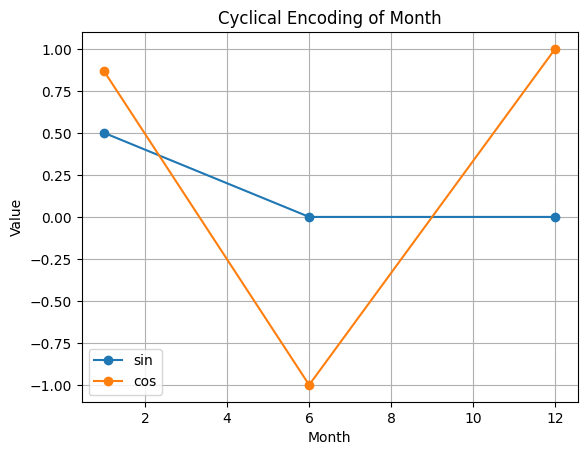

In [ ]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(df["Month"], df["Month_sin"], marker='o', label="sin")
plt.plot(df["Month"], df["Month_cos"], marker='o', label="cos")

plt.xlabel("Month")
plt.ylabel("Value")
plt.title("Cyclical Encoding of Month")
plt.legend()
plt.grid()

plt.show()

**📌 Feature Creation**

🔹 What is Feature Creation?

Feature Creation means creating new features from existing data to improve model performance.

👉 In simple terms: We make new useful columns from old ones.

In [ ]:
import pandas as pd

data = {
    "Name": ["A", "B", "C"],
    "Price": [100, 200, 150],
    "Quantity": [2, 3, 5],
    "First_Name": ["John", "Jane", "Sam"],
    "Last_Name": ["Doe", "Smith", "Brown"],
    "Email": ["john@gmail.com", "jane@yahoo.com", "sam@outlook.com"]
}

df = pd.DataFrame(data)
df

,Name,Price,Quantity,First_Name,Last_Name,Email
0,A,100,2,John,Doe,john@gmail.com
1,B,200,3,Jane,Smith,jane@yahoo.com
2,C,150,5,Sam,Brown,sam@outlook.com


**Mathematical Feature Creation**

In [ ]:
# Create Total Price
df["Total_Price"] = df["Price"] * df["Quantity"]

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price
0,A,100,2,John,Doe,john@gmail.com,200
1,B,200,3,Jane,Smith,jane@yahoo.com,600
2,C,150,5,Sam,Brown,sam@outlook.com,750


**Combining Features**

In [ ]:
# Full Name
df["Full_Name"] = df["First_Name"] + " " + df["Last_Name"]

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name
0,A,100,2,John,Doe,john@gmail.com,200,John Doe
1,B,200,3,Jane,Smith,jane@yahoo.com,600,Jane Smith
2,C,150,5,Sam,Brown,sam@outlook.com,750,Sam Brown


**Extracting Information**

In [ ]:
# Extract email domain
df["Email_Domain"] = df["Email"].apply(lambda x: x.split("@")[1])
df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name,Email_Domain
0,A,100,2,John,Doe,john@gmail.com,200,John Doe,gmail.com
1,B,200,3,Jane,Smith,jane@yahoo.com,600,Jane Smith,yahoo.com
2,C,150,5,Sam,Brown,sam@outlook.com,750,Sam Brown,outlook.com


Domain-Based Feature (Example: BMI)
**bold text**

In [ ]:
# Add sample data
df["Weight"] = [60, 70, 80]   # kg
df["Height"] = [1.6, 1.7, 1.8]  # meters

# BMI Formula
df["BMI"] = df["Weight"] / (df["Height"] ** 2)

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name,Email_Domain,Weight,Height,BMI
0,A,100,2,John,Doe,john@gmail.com,200,John Doe,gmail.com,60,1.6,23.437500
1,B,200,3,Jane,Smith,jane@yahoo.com,600,Jane Smith,yahoo.com,70,1.7,24.221453
2,C,150,5,Sam,Brown,sam@outlook.com,750,Sam Brown,outlook.com,80,1.8,24.691358


**Check Missing Values**

In [ ]:
df.isnull().sum()

,0
Age,2
Salary,1
City,1


**Mean Imputation**

In [ ]:
df2 = df.copy()
df2["Age"] = df2["Age"].fillna(df2["Age"].mean())
df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,NaN,None
3,35.0,80000.0,Pune
4,30.0,90000.0,Delhi


**Median Imputation**

In [ ]:
df2 = df.copy()
df2["Salary"] = df2["Salary"].fillna(df2["Salary"].median())
df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,70000.0,None
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


**Mode Imputation**

In [ ]:
df2 = df.copy()
df2["City"] = df2["City"].fillna(df2["City"].mode()[0])
df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,NaN,Delhi
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


**Forward Fill**

In [ ]:
df_ffill = df.ffill()
df_ffill

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,25.0,60000.0,Delhi
2,30.0,60000.0,Delhi
3,35.0,80000.0,Pune
4,35.0,90000.0,Delhi


**Backward Fill**

In [ ]:
df_bfill = df.bfill()
df_bfill

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,80000.0,Pune
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


**Missing Indicator**

In [ ]:
df["Age_missing"] = df["Age"].isnull().astype(int)
df

,Age,Salary,City,Age_missing
0,25.0,50000.0,Mumbai,0
1,NaN,60000.0,Delhi,1
2,30.0,NaN,None,0
3,35.0,80000.0,Pune,0
4,NaN,90000.0,Delhi,1


📌 Feature Selection

🔹 What is Feature Selection?

Feature Selection means selecting the most important features for the model and removing unnecessary ones.

👉 In simple terms: Keep useful columns, remove useless ones.

In [ ]:
import pandas as pd

data = {
    "Age": [25, 30, 35, 40, 45],
    "Salary": [30000, 40000, 50000, 60000, 70000],
    "Experience": [1, 3, 5, 7, 9],
    "Purchased": [0, 0, 1, 1, 1]  # Target variable
}

df = pd.DataFrame(data)
df

,Age,Salary,Experience,Purchased
0,25,30000,1,0
1,30,40000,3,0
2,35,50000,5,1
3,40,60000,7,1
4,45,70000,9,1


**Correlation (Filter Method)**

In [ ]:
# Correlation matrix
#A correlation matrix is a table that shows how strongly two numerical variables are related to each other.
df.corr()

,Age,Salary,Experience,Purchased
Age,1.000000,1.000000,1.000000,0.866025
Salary,1.000000,1.000000,1.000000,0.866025
Experience,1.000000,1.000000,1.000000,0.866025
Purchased,0.866025,0.866025,0.866025,1.000000


Select Important Features (based on correlation)

In [ ]:
# Correlation with target
corr_with_target = df.corr()["Purchased"]
corr_with_target

,Purchased
Age,0.866025
Salary,0.866025
Experience,0.866025
Purchased,1.000000


**Drop Less Important Features**

In [ ]:
# Example: Drop a feature (if low importance)
df_selected = df.drop(columns=["Age"])  # just for demo
df_selected

,Salary,Experience,Purchased
0,30000,1,0
1,40000,3,0
2,50000,5,1
3,60000,7,1
4,70000,9,1


📌 Handling Outliers

🔹 What are Outliers?

Outliers are data points that are very different from the rest of the data.

👉 Example: Most salaries = 30k–50k
One salary = 5,00,000 → Outlier

In [ ]:
import pandas as pd

data = {
    "Salary": [30000, 35000, 40000, 45000, 50000, 1000000, 2]  # Outlier present
}

df = pd.DataFrame(data)
df

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,1000000
6,2


**Detect Outliers using IQR**

In [ ]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_bound, upper_bound

# Detect outliers
outliers = df[(df["Salary"] < lower_bound) | (df["Salary"] > upper_bound)]

print(outliers)

    Salary
5  1000000
6        2


**Remove Outliers**

In [ ]:
df_no_outliers = df[(df["Salary"] >= lower_bound) & (df["Salary"] <= upper_bound)]
df_no_outliers

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000


**Cap Outliers**

In [ ]:
df_capped = df.copy()

df_capped["Salary"] = df_capped["Salary"].clip(lower_bound, upper_bound)
df_capped

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,70000
6,10000


**Z-Score Method**

In [ ]:
from scipy import stats

z_scores = stats.zscore(df["Salary"])
z_scores

array([-0.41769094, -0.40292412, -0.3881573 , -0.37339047, -0.35862365,
        2.44707244, -0.50628596])

**Identify Outliers using Z-Score**

In [ ]:
df_z = df[(abs(z_scores) > 2)]
df_z

,Salary
5,1000000


In [ ]:
import pandas as pd

data = {
    "Salary": [30000, 35000, 40000, 45000, 50000, 1000000, 2]  # Outlier present
}

df = pd.DataFrame(data)
df

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,1000000
6,2


In [ ]:
import pandas as pd
import numpy as np

data = {
    "Age": [25, np.nan, 30, 35, np.nan],
    "Salary": [50000, 60000, np.nan, 80000, 90000],
    "City": ["Mumbai", "Delhi", None, "Pune", "Delhi"]
}

df = pd.DataFrame(data)
df

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,NaN,None
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("BankChurners.csv")
df

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.999910
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.999940
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.999980
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.999870
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.999980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,...,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462,0.000191,0.999810
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,...,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511,0.995270,0.004729
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,...,5409.0,0,5409.0,0.819,10291,60,0.818,0.000,0.997880,0.002118
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,...,5281.0,0,5281.0,0.535,8395,62,0.722,0.000,0.996710,0.003294


In [ ]:
df.shape

(10127, 23)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [ ]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [ ]:
df.columns

Index(['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender',
       'Dependent_count', 'Education_Level', 'Marital_Status',
       'Income_Category', 'Card_Category', 'Months_on_book',
       'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
       'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0
Months_on_book,0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

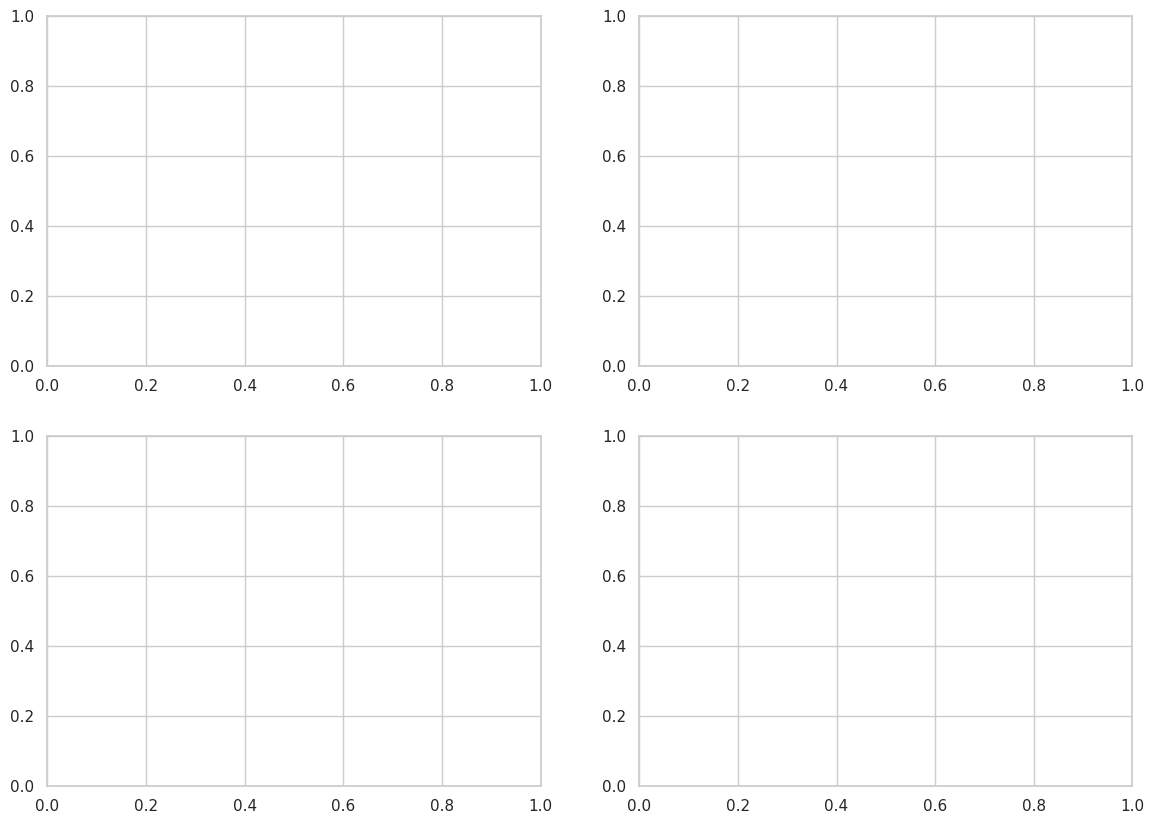

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

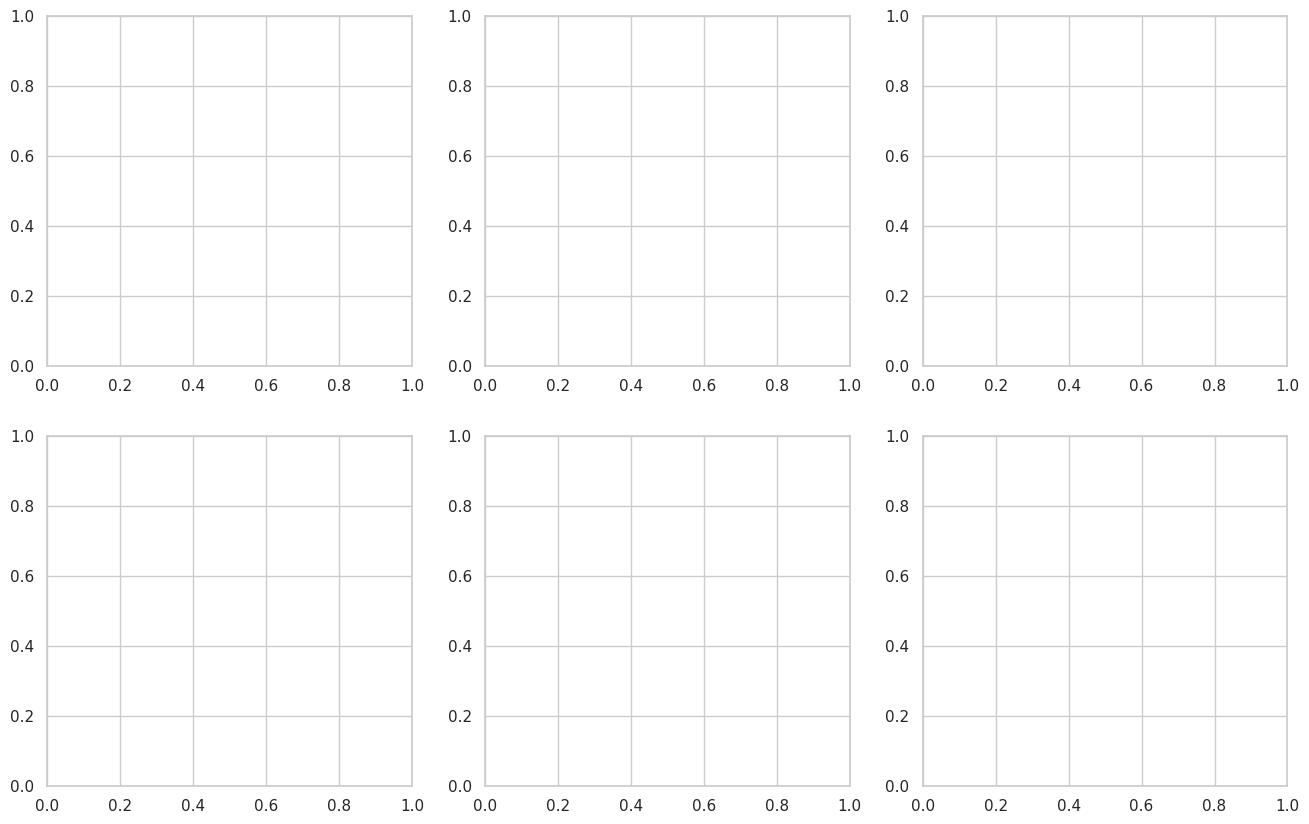

In [ ]:
features = [
    'Customer_Age', 'Credit_Limit', 'Total_Trans_Amt',
    'Total_Trans_Ct', 'Total_Revolving_Bal', 'Avg_Utilization_Ratio'
]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

In [ ]:
palette = {'Existing Customer': '#4C72B0', 'Attrited Customer': '#DD8452'}

for i, col in enumerate(features):
    sns.histplot(
        data=df,
        x=col,
        hue='Attrition_Flag',
        kde=True,
        ax=axes[i],
        palette=palette,
        bins=30,
        alpha=0.5
    )
    axes[i].set_title(f'Histogram of {col.replace("_", " ")}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col.replace('_', ' '))
    axes[i].set_ylabel('Frequency')

In [ ]:
plt.tight_layout()


<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig('bank_churners_histograms.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

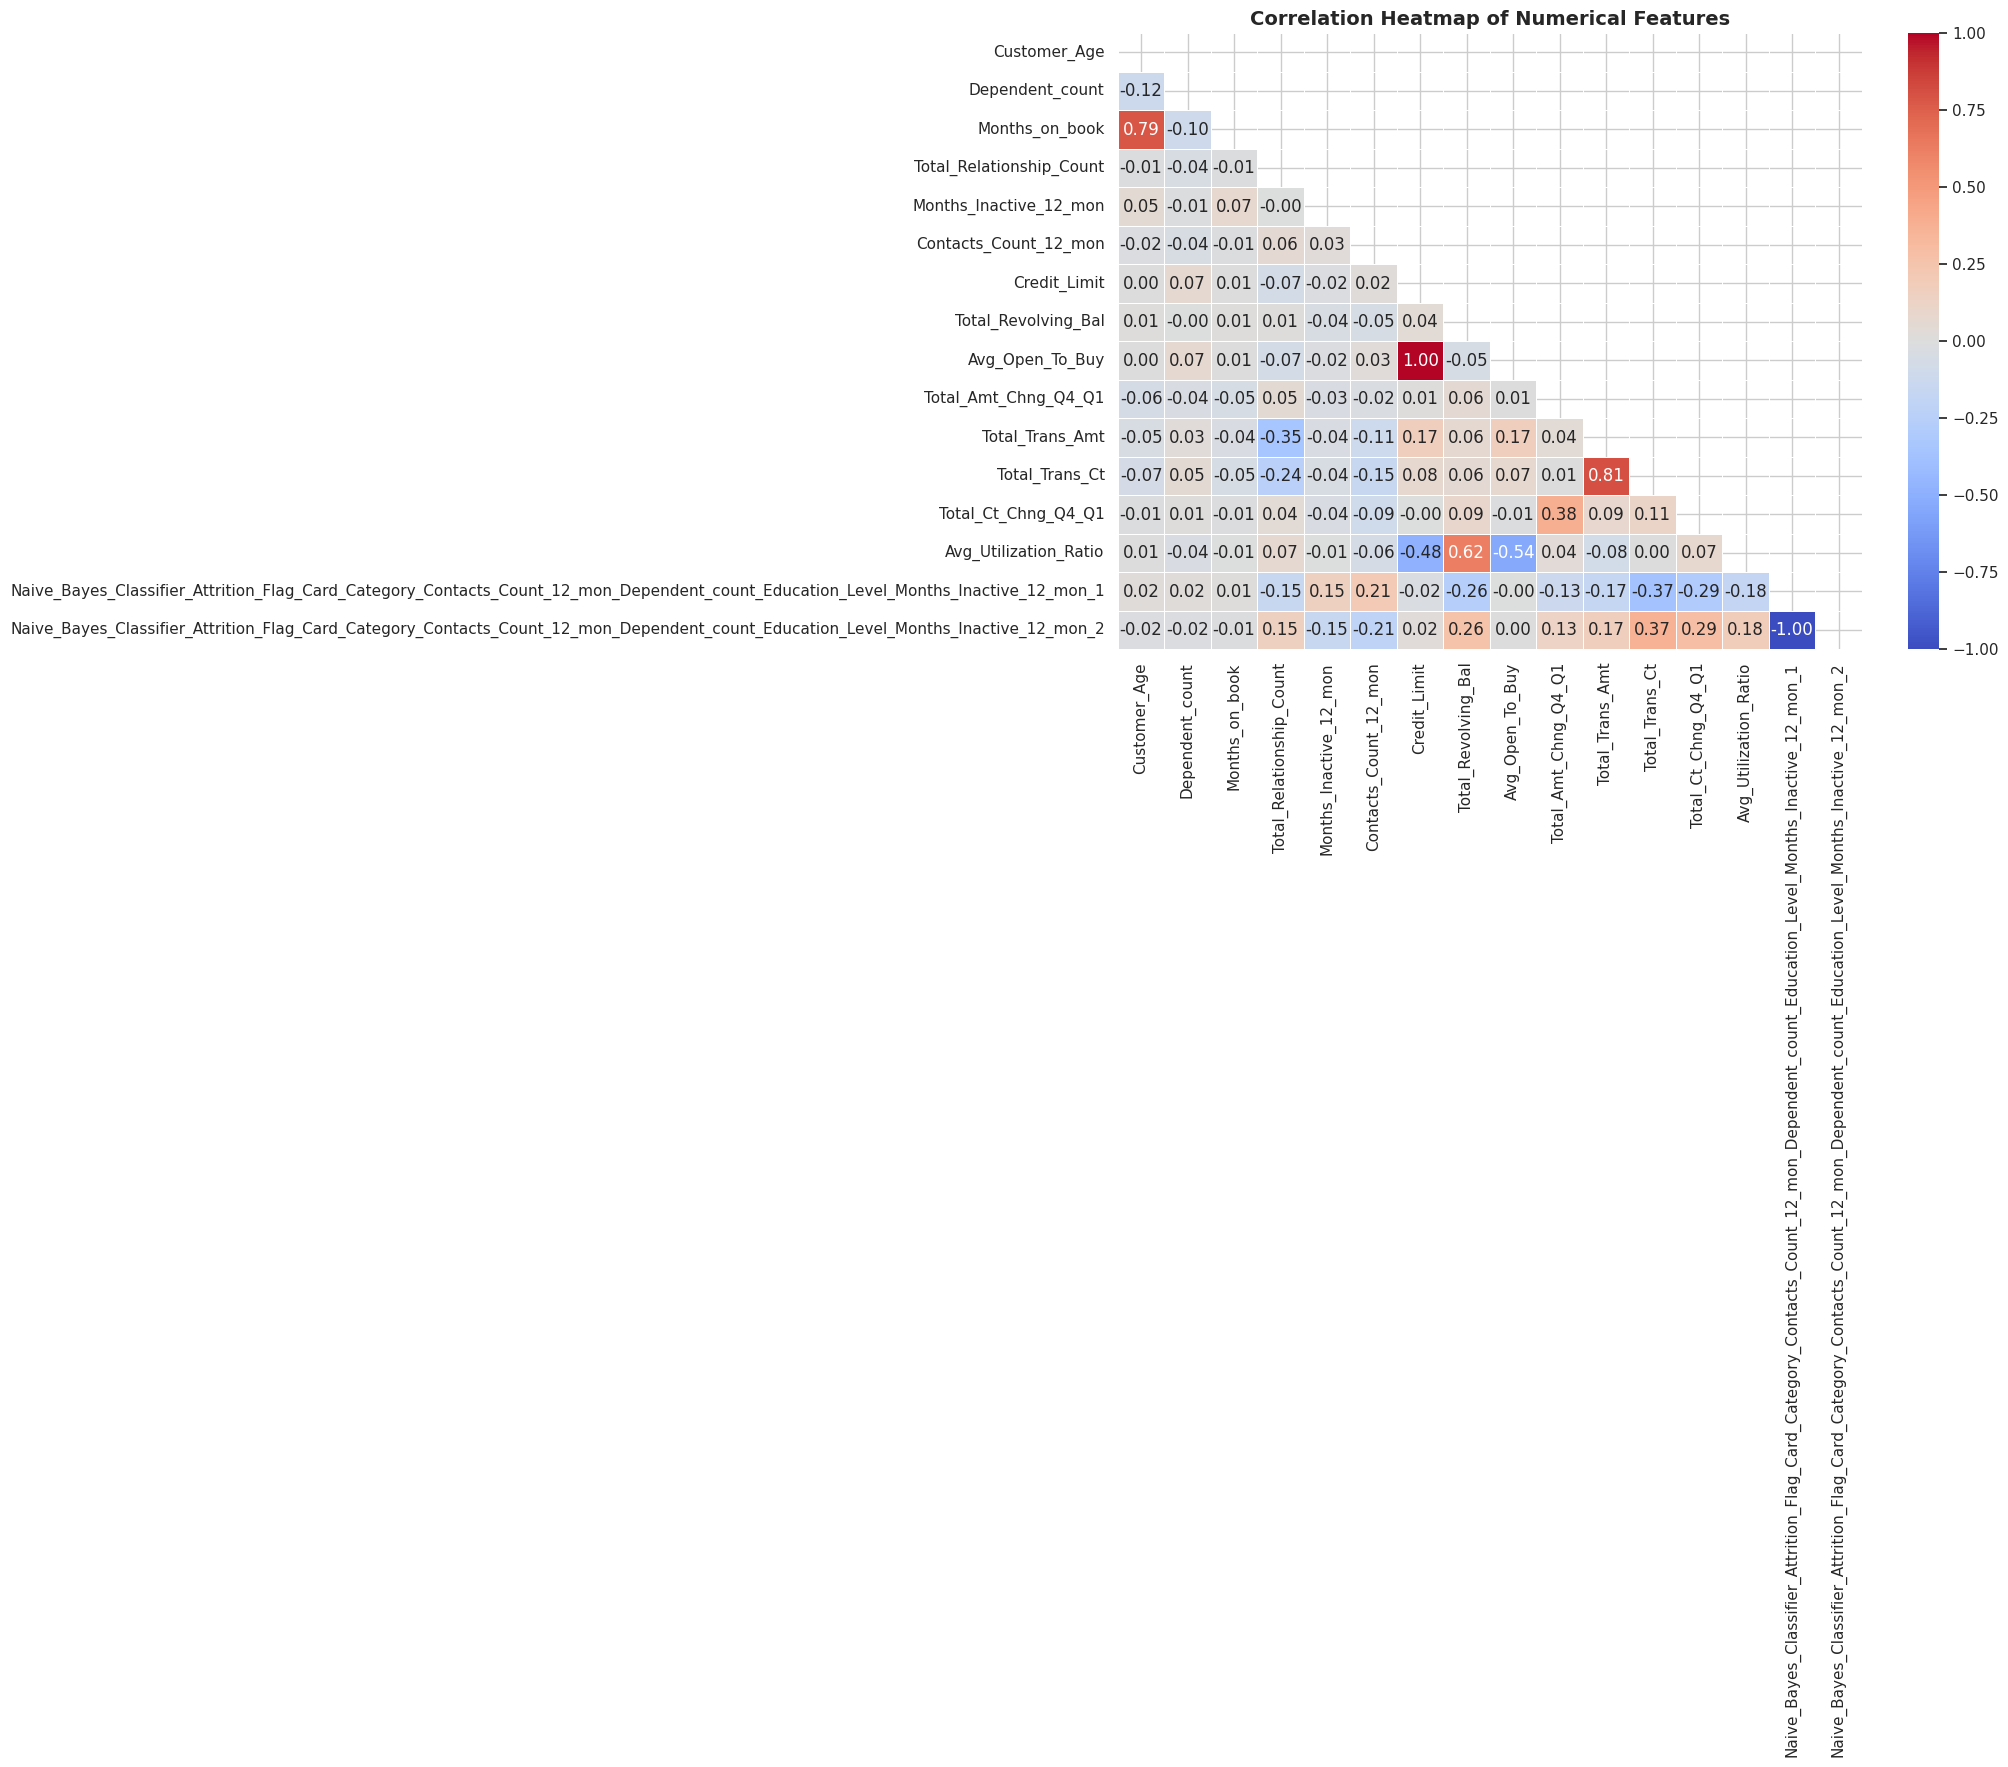

In [ ]:
plt.figure(figsize=(12, 8))
num_cols = df.select_dtypes(include=[np.number]).drop(columns=['CLIENTNUM'])
corr = num_cols.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold')
plt.show()